# 11-апта · Қолжазба цифрларын тану

**Орындағандар: Ақылбек пен Алмас.**

| Қорғаушы | Көрсететін бөлімдер |
|---|---|
| **Ақылбек** | DIGITS, 8×8 кіріс, 2 және 32 нейрон, Softmax және қолмен жазылған кері тарату |
| **Алмас** | MNIST, 28×28 кіріс, Keras архитектурасы, 5 эпоха, қате болжамдар, 128/256 және Tuner |

Colab-та **Run all** арқылы қайта орындауға болады. Пакеттер жетіспесе, жеке ұяшыққа
**%pip install -q numpy matplotlib scikit-learn tensorflow keras-tuner tensorboard** жаз.
Төмендегі сақталған нәтижелер есеп нақты орындалған кезде алынған.

In [1]:
import os
import json
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "4")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 42
OUT = Path(os.environ.get("WEEK11_OUT", "week11-results"))
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "figure.facecolor": "#f4f8f5",
    "axes.facecolor": "#f4f8f5", "axes.labelcolor": "#16392e",
    "text.color": "#16392e", "xtick.color": "#436658", "ytick.color": "#436658",
    "axes.spines.top": False, "axes.spines.right": False,
})


def save_plot(figure, name):
    path = OUT / name
    figure.savefig(path, dpi=150, bbox_inches="tight", pad_inches=.2)
    plt.close(figure)
    try:
        shell = get_ipython()
    except NameError:
        shell = None
    if shell is not None:
        from IPython.display import Image, display

        display(Image(filename=str(path)))


def image_grid(images, labels, name, headline, predictions=None, columns=5):
    rows = (len(images) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(2 * columns, 2 * rows + .3), squeeze=False)
    figure.suptitle(headline, fontsize=16, fontweight="bold")
    for i, axis in enumerate(axes.flat):
        axis.axis("off")
        if i >= len(images):
            continue
        axis.imshow(images[i], cmap="gray_r", vmin=0, vmax=1)
        label = str(int(labels[i]))
        if predictions is not None:
            label += f"  →  {int(predictions[i])}"
        axis.set_title(label, color="#ac4137" if predictions is not None and labels[i] != predictions[i] else "#176754")
    figure.tight_layout()
    save_plot(figure, name)


def cross_entropy(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())


def packed_samples(images, labels, probabilities, indices):
    return [{
        "index": int(i), "actual": int(labels[i]), "prediction": int(probabilities[i].argmax()),
        "pixels": np.rint(images[i].reshape(-1) * 255).astype(np.uint8).tolist(),
        "probabilities": probabilities[i].round(6).tolist(),
    } for i in indices]


def top_confusions(matrix, limit=5):
    counts = [(int(matrix[a, b]), a, b) for a in range(10) for b in range(10) if a != b]
    return [{"actual": a, "prediction": b, "count": count}
            for count, a, b in sorted(counts, key=lambda row: (-row[0], row[1], row[2]))[:limit] if count]

## 1 · Ақылбек: NumPy арқылы DIGITS

1 797 сурет, әрқайсысы 8×8. Пиксельді 16-ға бөліп, 64 сандық векторға айналдырамыз.
1 400 сурет оқытуға, 397 сурет тестке алынады. Бірдей бөлу мен 300 градиент
қадамында 2 және 32 жасырын нейронды салыстырамыз.

**Алға тарату:** $H=\tanh(XW_1+b_1)$, $Z=HW_2+b_2$,
$P_j=e^{Z_j-\max Z}/\sum_k e^{Z_k-\max Z}$.

**Шығын:** $L=-\frac{1}{n}\sum_i \log P_{i,y_i}$.
Әр жолдан тек дұрыс кластың ықтималдығын аламыз.

**Кері тарату:** $dZ=(P-Y)/n$, $dH=(dZ W_2^\top)\odot(1-H^2)$,
$dW_2=H^\top dZ$, $dW_1=X^\top dH$, $W\gets W-\eta dW$.
Мұндағы $Y$ — one-hot жауап, $\eta=0.3$, mini-batch көлемі 64.

**Экранда көрсет:** екі оқыту қисығын және 32 салмақ картасын. Карта — нейронның
кіріс пиксельдеріне берген оң және теріс салмақтары.

DIGITS train/test: 1400/397
 2 hidden units: test accuracy 46.85%
32 hidden units: test accuracy 97.23%
Correct: 386/397


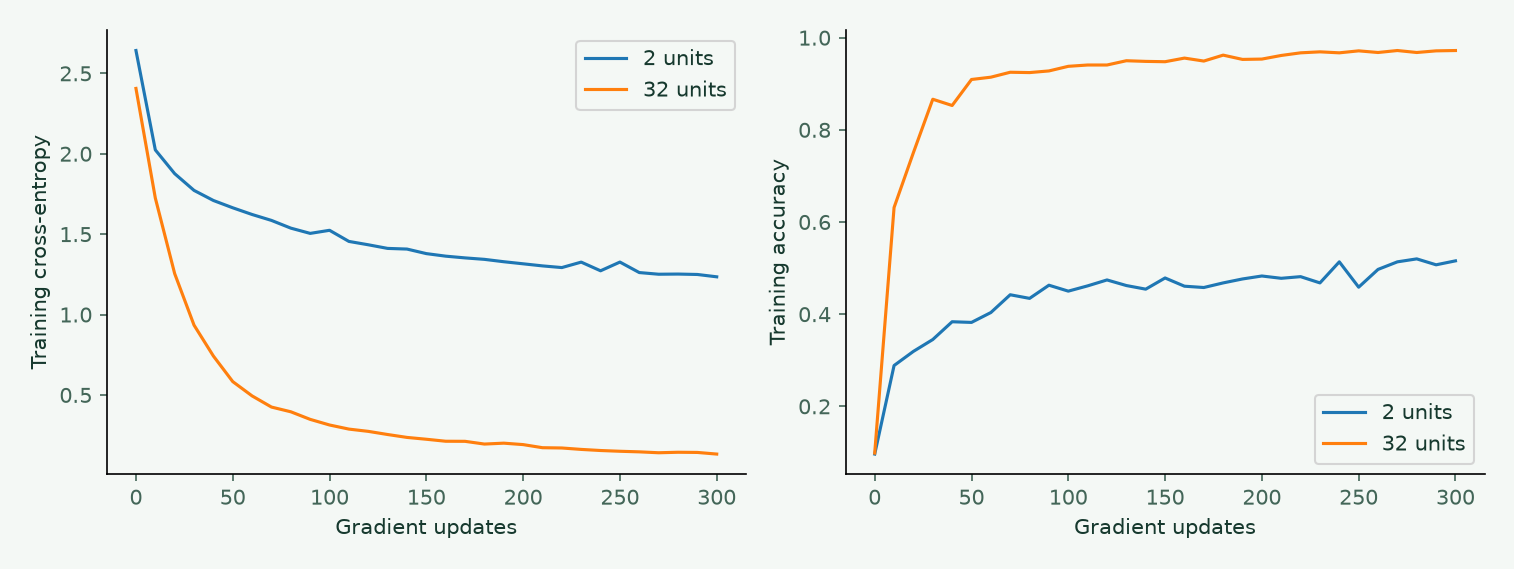

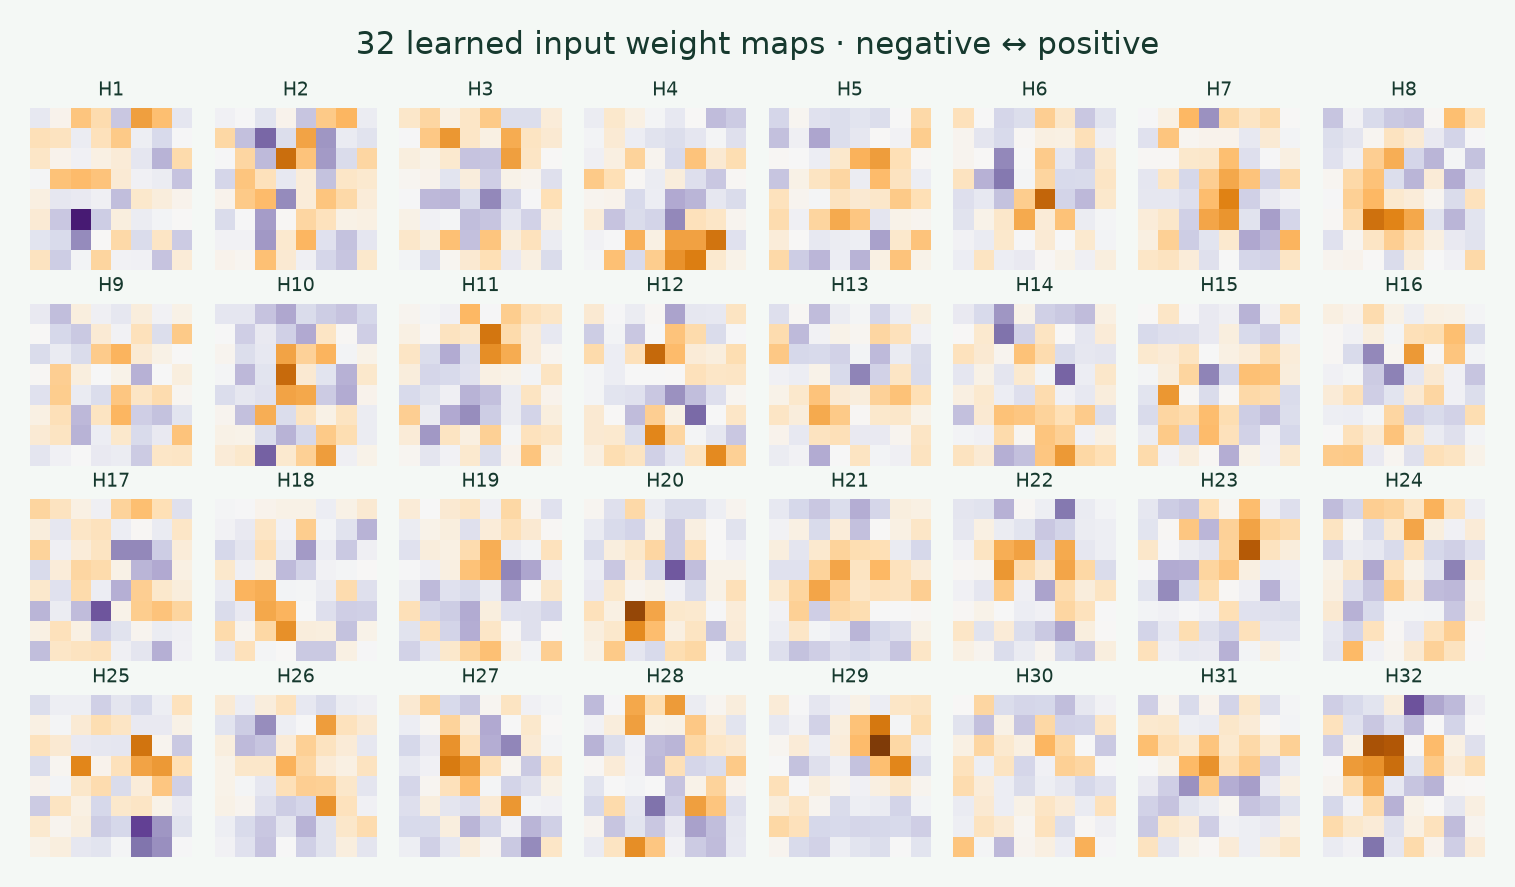

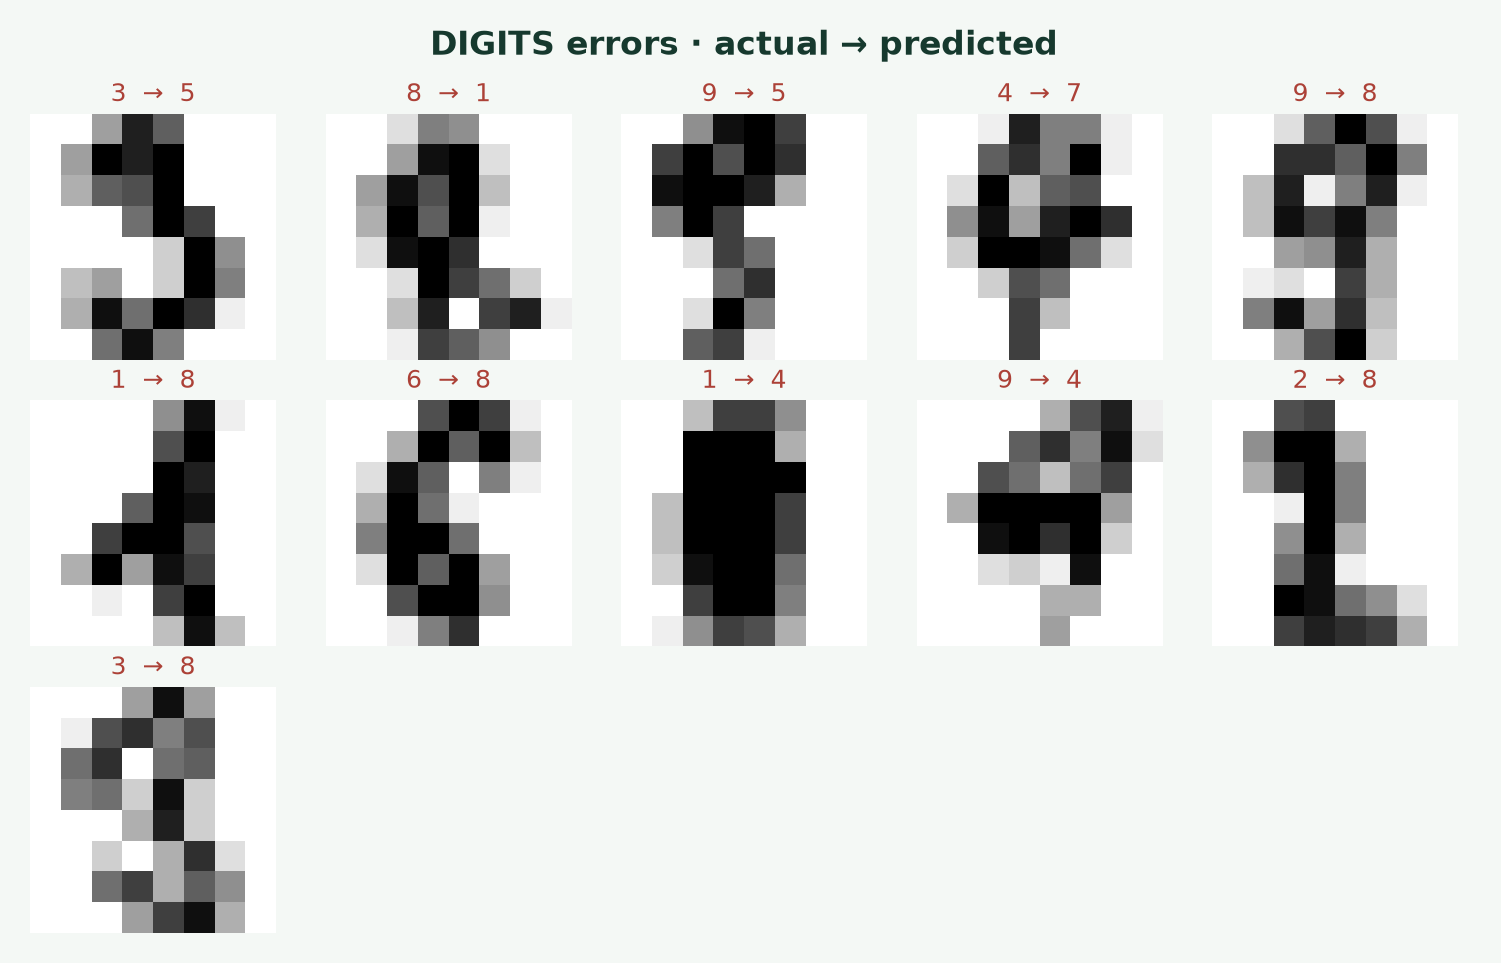

In [2]:
digits = load_digits()
digits_x = digits.data / 16.0
digits_y = digits.target


def train_digits(width, steps=300, learning_rate=.3):
    rng = np.random.default_rng(0)
    order = rng.permutation(len(digits_x))
    train, test = order[:1400], order[1400:]
    w1 = rng.normal(0, 1 / np.sqrt(64), (64, width))
    w2 = rng.normal(0, 1 / np.sqrt(width), (width, 10))
    b1, b2 = np.zeros(width), np.zeros(10)

    def forward(x):
        hidden = np.tanh(x @ w1 + b1)
        logits = hidden @ w2 + b2
        scores = np.exp(logits - logits.max(axis=1, keepdims=True))
        return hidden, scores / scores.sum(axis=1, keepdims=True)

    history = []
    for step in range(steps + 1):
        if step % 10 == 0 or step == steps:
            train_p = forward(digits_x[train])[1]
            history.append({
                "step": step, "loss": cross_entropy(train_p, digits_y[train]),
                "accuracy": float((train_p.argmax(axis=1) == digits_y[train]).mean()),
            })
        if step == steps:
            break
        batch = rng.choice(train, 64)
        x, y = digits_x[batch], digits_y[batch]
        hidden, probabilities = forward(x)
        dlogits = probabilities.copy()
        dlogits[np.arange(len(y)), y] -= 1
        dlogits /= len(y)
        dhidden = (dlogits @ w2.T) * (1 - hidden**2)
        w2 -= learning_rate * (hidden.T @ dlogits)
        b2 -= learning_rate * dlogits.sum(axis=0)
        w1 -= learning_rate * (x.T @ dhidden)
        b1 -= learning_rate * dhidden.sum(axis=0)

    hidden, probabilities = forward(digits_x[test])
    accuracy = float((probabilities.argmax(axis=1) == digits_y[test]).mean())
    return dict(test=test, w1=w1, hidden=hidden, p=probabilities, history=history, accuracy=accuracy)


digits_small = train_digits(2)
digits_full = train_digits(32)
digits_test = digits_full["test"]
digits_actual = digits_y[digits_test]
digits_pred = digits_full["p"].argmax(axis=1)
digits_wrong = np.flatnonzero(digits_pred != digits_actual)
print(f"DIGITS train/test: 1400/{len(digits_test)}")
for width, result in [(2, digits_small), (32, digits_full)]:
    print(f"{width:2d} hidden units: test accuracy {result['accuracy']:.2%}")
print(f"Correct: {len(digits_test) - len(digits_wrong)}/{len(digits_test)}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for width, result in [(2, digits_small), (32, digits_full)]:
    points = result["history"]
    axes[0].plot([p["step"] for p in points], [p["loss"] for p in points], label=f"{width} units")
    axes[1].plot([p["step"] for p in points], [p["accuracy"] for p in points], label=f"{width} units")
for ax, label in zip(axes, ["Training cross-entropy", "Training accuracy"]):
    ax.set(xlabel="Gradient updates", ylabel=label)
    ax.legend()
fig.tight_layout()
save_plot(fig, "digits-training.png")

fig, axes = plt.subplots(4, 8, figsize=(10, 5.8))
weights = digits_full["w1"]
limit = float(np.abs(weights).max())
for i, axis in enumerate(axes.flat):
    axis.imshow(weights[:, i].reshape(8, 8), cmap="PuOr", vmin=-limit, vmax=limit)
    axis.set_title(f"H{i + 1}", fontsize=9)
    axis.axis("off")
fig.suptitle("32 learned input weight maps · negative ↔ positive", fontsize=15)
fig.tight_layout()
save_plot(fig, "digits-weights.png")

image_grid(digits_x[digits_test[digits_wrong]].reshape(-1, 8, 8),
           digits_actual[digits_wrong], "digits-errors.png", "DIGITS errors · actual → predicted",
           digits_pred[digits_wrong])

## 2 · Алмас: MNIST дерегі және архитектура

MNIST суреті 28×28. Пиксель мәндері $x'=x/255$ арқылы 0–1 аралығына келтіріледі.
Алғашқы 10 сурет нақты белгілерімен көрсетіледі. Ресми оқыту жиынының
10%-ын validation үшін бөлеміз. Ресми 10 000 тест кескіні модельді оқытуға немесе
гиперпараметр іздеуге қатыспайды.

**Архитектура:** 28×28 → Flatten(784) → Dense(128, ReLU) → Dropout(0.2) → Dense(10).
$\operatorname{ReLU}(z)=\max(0,z)$. Dropout оқытуда ғана іске қосылады.
Соңғы қабат 10 логит береді. **from_logits=True** шығынды тұрақты есептейді.
Болжамды түсіндіру үшін Softmax бөлек қолданылады.

TensorFlow: 2.21.0
MNIST: train=54000, validation=6000, test=10000; normalized range [0, 1]


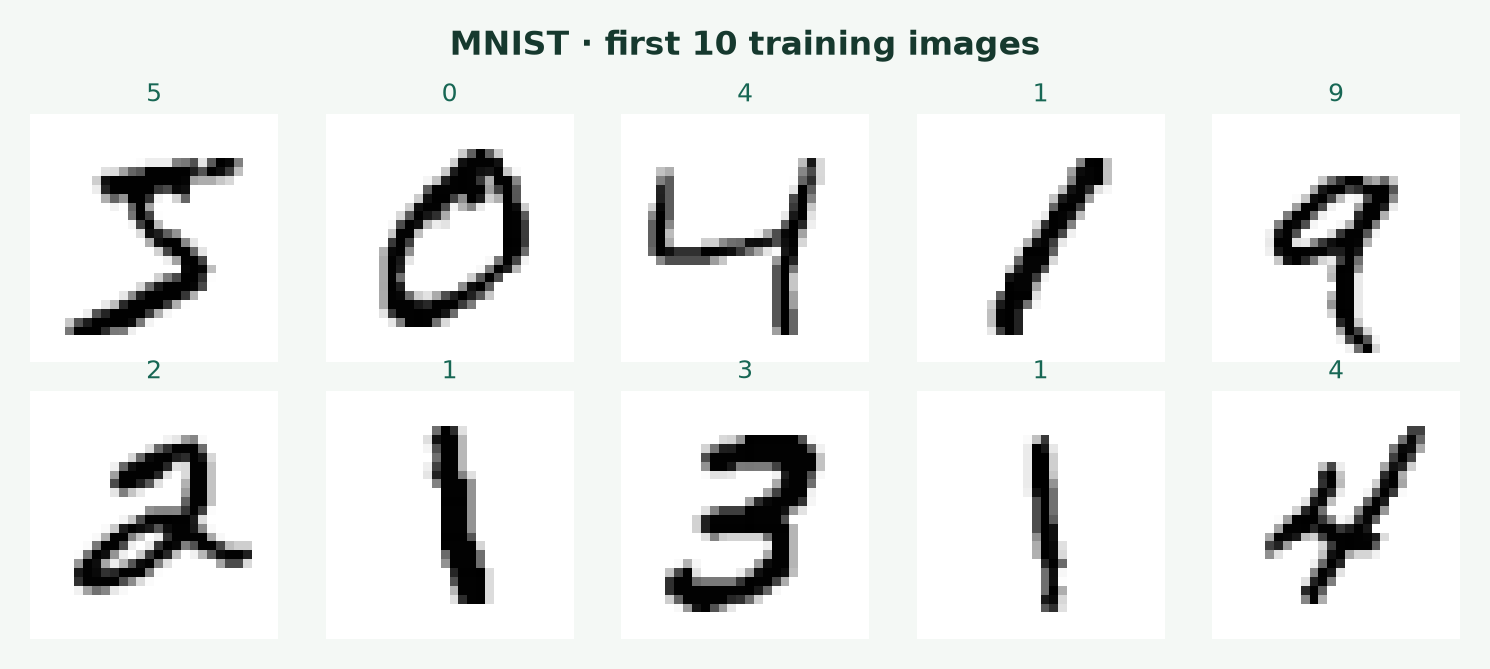

In [3]:
import tensorflow as tf
import keras_tuner as kt

tf.keras.utils.set_random_seed(SEED)
mnist_file = os.environ.get("WEEK11_MNIST_FILE")
if mnist_file:
    with np.load(mnist_file) as data:
        (x_all, y_all), (x_test, y_test) = (data["x_train"], data["y_train"]), (data["x_test"], data["y_test"])
else:
    (x_all, y_all), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_all = x_all.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
train_indices, val_indices = train_test_split(np.arange(len(y_all)), test_size=.1, random_state=SEED, stratify=y_all)
x_train, y_train = x_all[train_indices], y_all[train_indices]
x_val, y_val = x_all[val_indices], y_all[val_indices]
print("TensorFlow:", tf.__version__)
print(f"MNIST: train={len(y_train)}, validation={len(y_val)}, test={len(y_test)}; normalized range [0, 1]")
image_grid(x_all[:10], y_all[:10], "mnist-training-samples.png", "MNIST · first 10 training images")


def batches(x, y, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        dataset = dataset.shuffle(10_000, seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 2
    return dataset.batch(128).with_options(options).prefetch(1)


train_data = batches(x_train, y_train, shuffle=True)
val_data = batches(x_val, y_val)
test_data = batches(x_test, y_test)


def build_mnist(units=128, rate=1e-3):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(units, activation="relu"),
        tf.keras.layers.Dropout(.2),
        tf.keras.layers.Dense(10),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    return model

## 3 · Бес эпоха және 128 / 256 салыстыруы

Екі нұсқада бірдей train/validation/test бөлінісі, Adam (0.001), 128 суреттік batch
және 5 эпоха қолданылады. Accuracy, cross-entropy және параметр санын салыстырамыз.
Бір эпоха — оқыту деректерін бір рет толық өту.

In [4]:
def run_mnist(name, units, rate):
    tf.keras.utils.set_random_seed(SEED)
    model = build_mnist(units, rate)
    history = model.fit(train_data, validation_data=val_data, epochs=5, verbose=2).history
    loss, accuracy = model.evaluate(test_data, verbose=0)
    summary = dict(name=name, units=units, rate=rate, parameters=model.count_params(),
                   test_loss=float(loss), accuracy=float(accuracy), history=history)
    print(f"{name}: test accuracy={accuracy:.2%}; test loss={loss:.4f}; parameters={model.count_params():,}")
    return model, summary


baseline, result_128 = run_mnist("Dense 128", 128, 1e-3)
wide, result_256 = run_mnist("Dense 256", 256, 1e-3)

Epoch 1/5
422/422 - 2s - 4ms/step - accuracy: 0.8808 - loss: 0.4178 - val_accuracy: 0.9357 - val_loss: 0.2275
Epoch 2/5
422/422 - 1s - 2ms/step - accuracy: 0.9408 - loss: 0.2040 - val_accuracy: 0.9537 - val_loss: 0.1655
Epoch 3/5
422/422 - 1s - 3ms/step - accuracy: 0.9546 - loss: 0.1545 - val_accuracy: 0.9630 - val_loss: 0.1356
Epoch 4/5
422/422 - 1s - 2ms/step - accuracy: 0.9626 - loss: 0.1261 - val_accuracy: 0.9690 - val_loss: 0.1152
Epoch 5/5
422/422 - 1s - 2ms/step - accuracy: 0.9691 - loss: 0.1060 - val_accuracy: 0.9670 - val_loss: 0.1071
Dense 128: test accuracy=97.12%; test loss=0.0978; parameters=101,770
Epoch 1/5
422/422 - 2s - 5ms/step - accuracy: 0.9011 - loss: 0.3481 - val_accuracy: 0.9475 - val_loss: 0.1827
Epoch 2/5
422/422 - 1s - 3ms/step - accuracy: 0.9543 - loss: 0.1555 - val_accuracy: 0.9618 - val_loss: 0.1353
Epoch 3/5
422/422 - 1s - 3ms/step - accuracy: 0.9667 - loss: 0.1138 - val_accuracy: 0.9677 - val_loss: 0.1062
Epoch 4/5
422/422 - 1s - 3ms/step - accuracy: 0.97

## 4 · Қосымша: Keras Tuner

RandomSearch төрт конфигурацияны тексереді. Кандидаттар: **64, 128, 256** нейрон және
оқыту жылдамдығы **0.0003, 0.001, 0.003**. Әр сынақ 3 эпоха жүреді.
Таңдау көрсеткіші — val_accuracy. Таңдалған конфигурация жаңадан 5 эпоха оқытылып,
бірдей тест жиынында өлшенеді. Бұл — тексерілген төрт нұсқаның ішіндегі үздік.

In [5]:
def hypermodel(hp):
    units = hp.Choice("units", [64, 128, 256])
    rate = hp.Choice("learning_rate", [3e-4, 1e-3, 3e-3])
    return build_mnist(units, rate)


tf.keras.utils.set_random_seed(SEED)
tuner = kt.RandomSearch(hypermodel, objective="val_accuracy", max_trials=4, seed=SEED,
                        directory=str(OUT / "tuner"), project_name="mnist", overwrite=True)
tuner.search(train_data, validation_data=val_data, epochs=3, verbose=0)
trials = [{"units": int(trial.hyperparameters.get("units")),
           "rate": float(trial.hyperparameters.get("learning_rate")), "val_accuracy": float(trial.score)}
          for trial in tuner.oracle.get_best_trials(4) if trial.score is not None]
best = tuner.get_best_hyperparameters(1)[0]
print("Tuner trials (validation only):", trials)
print(f"Selected units={best.get('units')}; Adam learning rate={best.get('learning_rate')}")
tuned, result_tuned = run_mnist("Tuned", best.get("units"), best.get("learning_rate"))

Tuner trials (validation only): [{'units': 256, 'rate': 0.001, 'val_accuracy': 0.9695000052452087}, {'units': 64, 'rate': 0.001, 'val_accuracy': 0.9509999752044678}, {'units': 256, 'rate': 0.0003, 'val_accuracy': 0.9495000243186951}, {'units': 128, 'rate': 0.0003, 'val_accuracy': 0.9396666884422302}]
Selected units=256; Adam learning rate=0.001
Epoch 1/5
422/422 - 2s - 5ms/step - accuracy: 0.9004 - loss: 0.3488 - val_accuracy: 0.9482 - val_loss: 0.1811
Epoch 2/5
422/422 - 2s - 4ms/step - accuracy: 0.9538 - loss: 0.1586 - val_accuracy: 0.9625 - val_loss: 0.1328
Epoch 3/5
422/422 - 1s - 3ms/step - accuracy: 0.9663 - loss: 0.1132 - val_accuracy: 0.9698 - val_loss: 0.1070
Epoch 4/5
422/422 - 1s - 3ms/step - accuracy: 0.9741 - loss: 0.0887 - val_accuracy: 0.9677 - val_loss: 0.1013
Epoch 5/5
422/422 - 1s - 3ms/step - accuracy: 0.9787 - loss: 0.0730 - val_accuracy: 0.9763 - val_loss: 0.0847
Tuned: test accuracy=97.67%; test loss=0.0754; parameters=203,530


## 5 · Алғашқы 10 болжам және қателер

Базалық 128 нейрондық желіге тест кескіндерін береміз. Softmax ықтималдықтарының
ең үлкен индексі — болжам: $\hat y=\arg\max_j P_j$. Accuracy — дұрыс болжамдар
санының барлық тест санына қатынасы.

Қателер матрицасында **жол — нақты цифр**, **баған — болжам**. Диагональ дұрыс жауаптарды,
қалған ұяшықтар нақты цифрдың қай цифрға шатасқанын көрсетеді.

Dense 128   128  0.001  97.12%  loss=0.0978
Dense 256   256  0.001  97.53%  loss=0.0789
Tuned       256  0.001  97.67%  loss=0.0754
Baseline correct: 9712/10000; errors: 288
Most frequent directed mistakes: [{'actual': 8, 'prediction': 3, 'count': 23}, {'actual': 5, 'prediction': 3, 'count': 22}, {'actual': 2, 'prediction': 3, 'count': 16}, {'actual': 9, 'prediction': 3, 'count': 15}, {'actual': 9, 'prediction': 4, 'count': 13}]


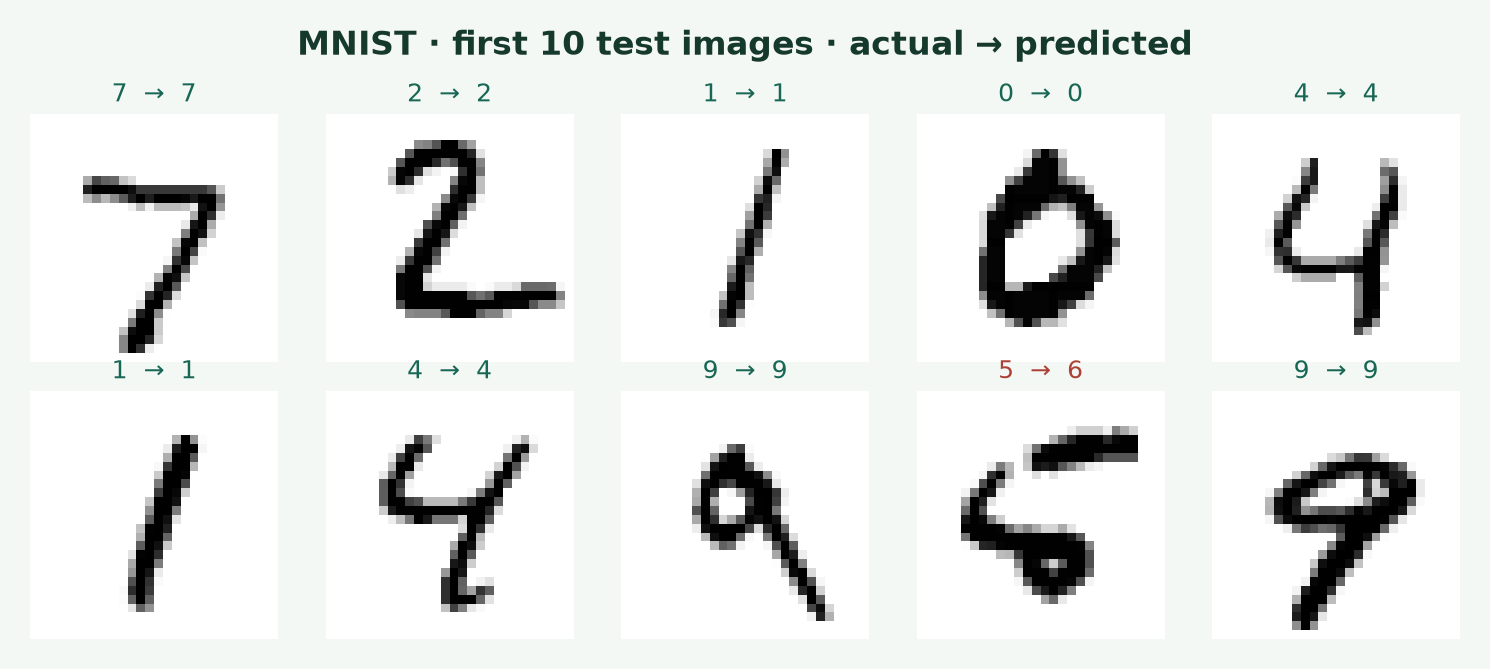

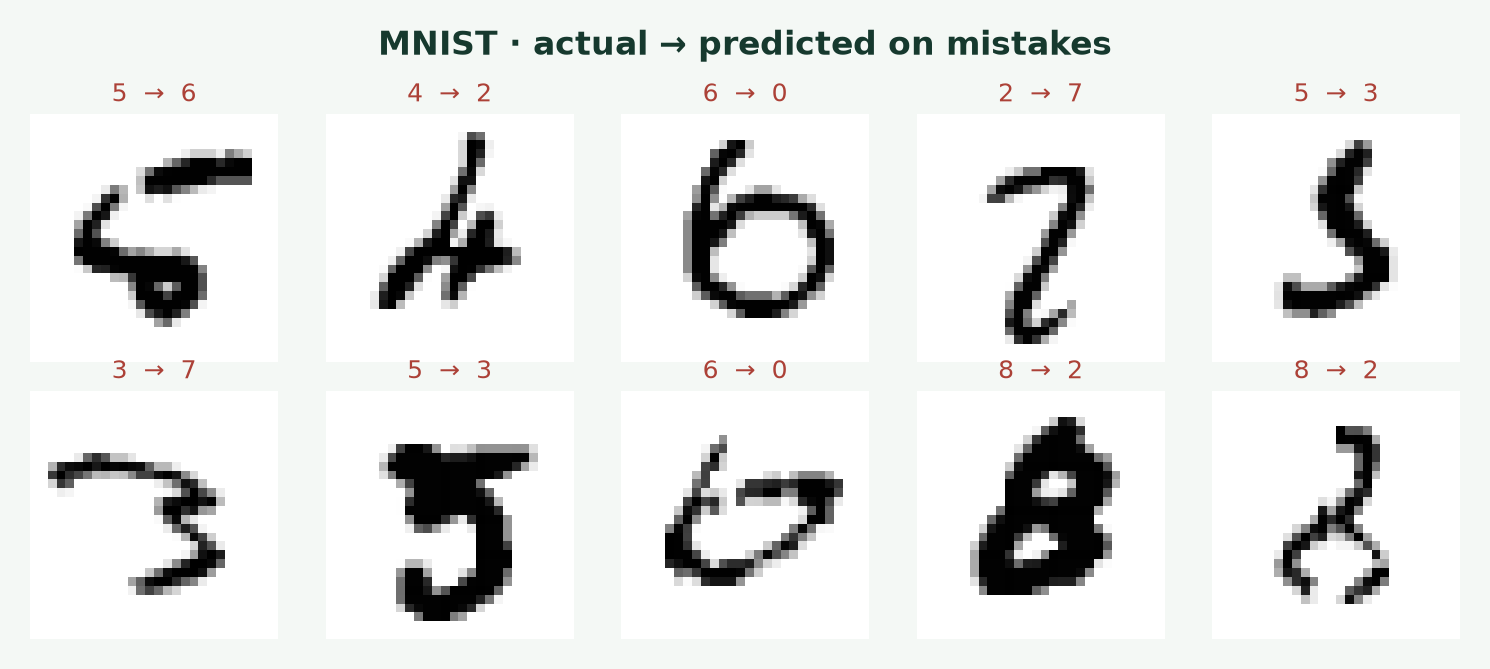

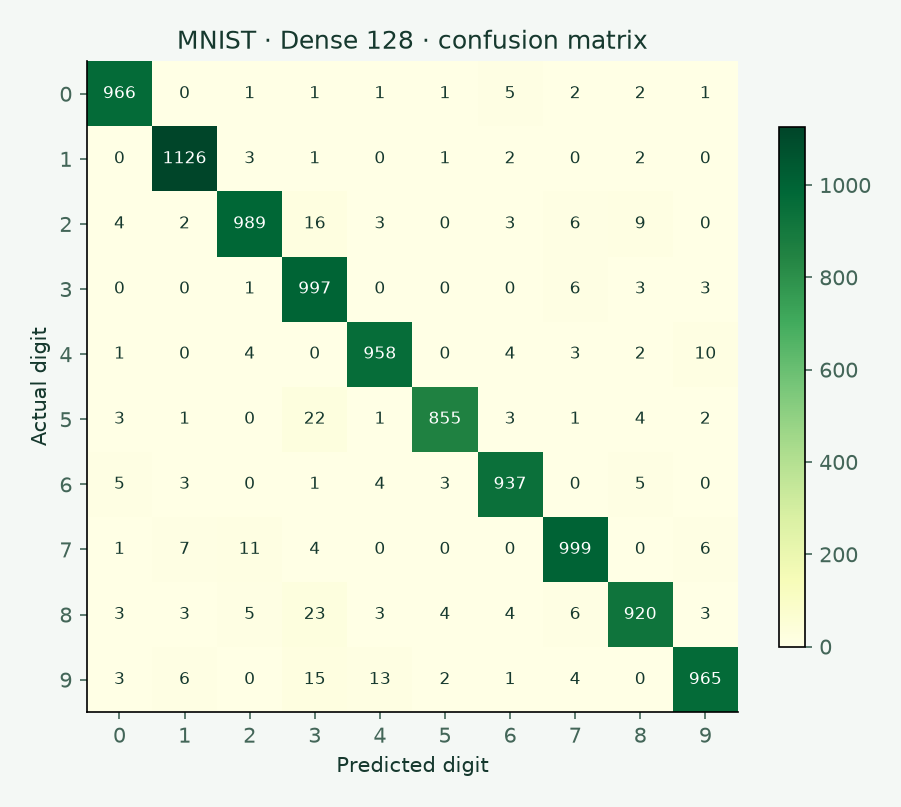

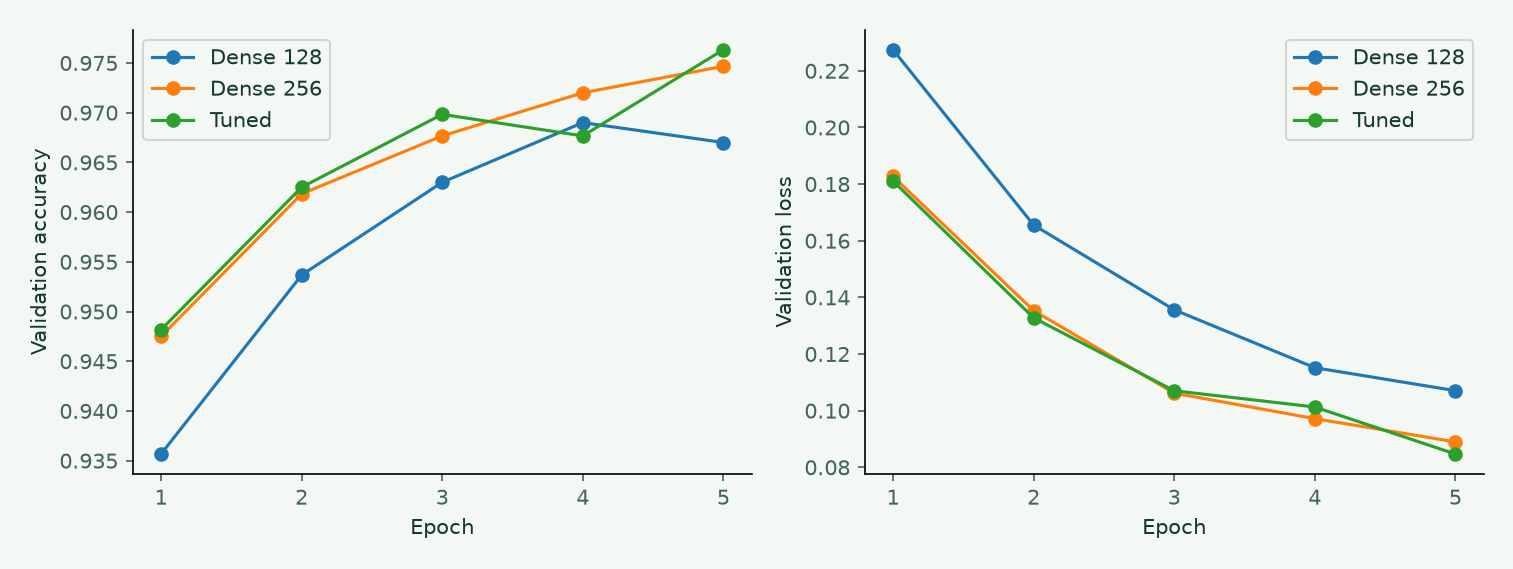

In [6]:
results = [result_128, result_256, result_tuned]
for result in results:
    print(f"{result['name']:10}  {result['units']:3}  {result['rate']:.4g}  "
          f"{result['accuracy']:.2%}  loss={result['test_loss']:.4f}")

logits = np.concatenate([baseline(x, training=False).numpy() for x, _ in test_data], axis=0)
probabilities = tf.nn.softmax(logits, axis=1).numpy()
predictions = probabilities.argmax(axis=1)
matrix = confusion_matrix(y_test, predictions, labels=np.arange(10))
errors = np.flatnonzero(y_test != predictions)
confusions = top_confusions(matrix)
print(f"Baseline correct: {len(y_test)-len(errors)}/{len(y_test)}; errors: {len(errors)}")
print("Most frequent directed mistakes:", confusions)
image_grid(x_test[:10], y_test[:10], "mnist-predictions.png", "MNIST · first 10 test images · actual → predicted", predictions[:10])
image_grid(x_test[errors[:10]], y_test[errors[:10]], "mnist-errors.png", "MNIST · actual → predicted on mistakes", predictions[errors[:10]])

fig, axis = plt.subplots(figsize=(7, 6))
heatmap = axis.imshow(matrix, cmap="YlGn", vmin=0)
axis.set(xlabel="Predicted digit", ylabel="Actual digit", xticks=range(10), yticks=range(10),
         title="MNIST · Dense 128 · confusion matrix")
for a in range(10):
    for b in range(10):
        axis.text(b, a, str(matrix[a, b]), ha="center", va="center",
                  color="white" if matrix[a, b] > matrix.max() * .55 else "#16392e", fontsize=8)
fig.colorbar(heatmap, ax=axis, shrink=.75)
save_plot(fig, "mnist-matrix.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for result in results:
    axes[0].plot(range(1, 6), result["history"]["val_accuracy"], marker="o", label=result["name"])
    axes[1].plot(range(1, 6), result["history"]["val_loss"], marker="o", label=result["name"])
for ax, label in zip(axes, ["Validation accuracy", "Validation loss"]):
    ax.set(xlabel="Epoch", ylabel=label, xticks=range(1, 6))
    ax.legend()
fig.tight_layout()
save_plot(fig, "mnist-training.png")

digit_examples = np.unique(np.r_[np.flatnonzero(digits_actual == 1)[:1], np.flatnonzero(digits_actual == 3)[:1],
                                  digits_wrong])
digit_samples = packed_samples(digits_x[digits_test].reshape(-1, 8, 8), digits_actual, digits_full["p"], digit_examples)
for sample in digit_samples:
    index = sample["index"]
    sample["activations"] = digits_full["hidden"][index].round(4).tolist()

payload = {
    "digits": {"accuracy2": digits_small["accuracy"], "accuracy32": digits_full["accuracy"],
               "testCount": len(digits_test), "errors": len(digits_wrong), "samples": digit_samples,
               "history2": digits_small["history"], "history32": digits_full["history"],
               "weights": weights.T.round(4).tolist()},
    "mnist": {"models": results, "trials": trials, "matrix": matrix.tolist(), "top": confusions,
              "trainCount": len(y_train), "validationCount": len(y_val), "testCount": len(y_test),
              "errors": len(errors), "tensorflow": tf.__version__,
              "first": packed_samples(x_test, y_test, probabilities, range(10)),
              "mistakes": packed_samples(x_test, y_test, probabilities, errors[:10]),
              "training": [{"actual": int(y_all[i]), "pixels": np.rint(x_all[i].reshape(-1) * 255).astype(np.uint8).tolist()}
                           for i in range(10)]},
}
(OUT / "week11-results.json").write_text(json.dumps(payload, ensure_ascii=False), encoding="utf-8")

## 6 · Қорытынды және қорғау сөзі

**Ақылбек:** «DIGITS-те 32 нейрондық желі 397 тест цифрының
**386** данасын дұрыс таныды, дәлдігі **97.23%**.
2 нейронмен дәлдік **46.85%** болды. Енді Алмас MNIST нәтижесін көрсетеді.»

| Модель | Нейрон | Adam LR | Параметр | Test accuracy | Test loss |
|---|---:|---:|---:|---:|---:|
| Dense 128 | 128 | 0.001 | 101,770 | 97.12% | 0.0978 |
| Dense 256 | 256 | 0.001 | 203,530 | 97.53% | 0.0789 |
| Tuned | 256 | 0.001 | 203,530 | 97.67% | 0.0754 |

**Алмас:** «Базалық модель 10 000 тест кескінінің **9712** данасын
дұрыс таныды. Ең жиі қателер: **8 → 3 (23 рет), 5 → 3 (22 рет), 2 → 3 (16 рет)**. Тест жиыны Tuner таңдауы кезінде қолданылған жоқ.»

**Сапаны жақсарту:** validation нәтижесімен CNN моделін салыстыру; ұқсас цифрлардың қателерін
бөлек қарау; оқытуда ғана шағын бұрылыс пен ығысу арқылы деректі көбейтіп көру.
128 және 256 айырмасы бір іске қосу бойынша өлшенген, тұрақтылықты бағалау үшін бірнеше seed керек.

**Ықтимал сұрақтар**

- *Неге Softmax-ты шығынға дейін қоспадық?* from_logits=True логиттерден cross-entropy-ді тікелей есептейді.
- *Неге test пен validation бөлек?* Validation баптауға қолданылады; test соңғы тәуелсіз бағалауға сақталады.
- *Dropout қашан қосылады?* Тек оқытуда. Болжамда training=False.
- *Дәлдік екі деректе неге тікелей салыстырылмайды?* Сурет өлшемі, дерек көлемі және бөлу тәсілі әртүрлі.

**Дереккөздер:** [DIGITS](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) ·
[TensorFlow MNIST](https://www.tensorflow.org/tutorials/quickstart/beginner) ·
[Keras Tuner](https://www.tensorflow.org/tutorials/keras/keras_tuner).

**Tuner туралы ескерту:** бұл іске қосуда Tuner 256 нейрондық нұсқамен бірдей баптауды таңдады. Екі тест нәтижесінің аз айырмасы бөлек оқытудағы mini-batch ретіне байланысты болуы мүмкін.
